# Chapitre 9 - Exercices 9.7 à 9.12

Ce notebook traite six exercices sur le décodage, l'attention et le service :

- **9.7** : accélération du décodage spéculatif, de la formule à la mesure ;
- **9.8** : cache KV de Llama 3-70B et nombre d'utilisateurs simultanés ;
- **9.9** : PagedAttention, choisir la taille des blocs ;
- **9.10** : batching dynamique, régler la fenêtre ;
- **9.11** : rentabilité du cache de prompt (stockage, durée de vie) et mesure du TTFT ;
- **9.12** : répartir Llama 3-70B sur 8 GPU (tenseur, pipeline, répliques).

In [1]:
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import KNOWN_CONFIGS, count_params_config, kv_cache_bytes, plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, COLORS,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
H100 = inf.ACCELERATORS["H100 SXM"]
GB = 1e9

## Exercice 9.7 : Accélération du décodage spéculatif

**Énoncé.**

1. On suppose que chaque token proposé est accepté avec probabilité $\alpha$,
   indépendamment, tant que les précédents l'ont été. Montrer que le nombre $J$ de tokens
   acceptés sur $k$ proposés suit $P(J = j) = \alpha^j(1 - \alpha)$ pour $j < k$ et
   $P(J = k) = \alpha^k$, puis que $\mathbb{E}[1 + J] = \frac{1 - \alpha^{k+1}}{1 - \alpha}$.
2. Exemple du livre (Chen et al., 2023) : brouillon de 4 milliards de paramètres à
   1,8 ms/token, cible Chinchilla-70B à 14,1 ms/token. Pour $\alpha = 0{,}8$, quel $k$
   maximise l'accélération ? La latence est-elle réduite « de plus de moitié » ?
3. Mini-lab : avec Qwen2.5-0.5B (brouillon) et Qwen2.5-1.5B (cible), $k = 6$, comparer la
   distribution observée de $J$ à la loi géométrique tronquée ajustée.

**Rappels.** Décodage spéculatif (cours 2, section 7 ; section *Speculative decoding*) :
accélération $S = \mathbb{E}[1 + J]/(kc + 1)$ avec $c$ le coût relatif d'un pas du
brouillon. Estimateur de $\alpha$ : acceptations / (acceptations + rejets).

**Solution.**

1. $J = j < k$ signifie : les $j$ premiers tokens acceptés (probabilité $\alpha^j$), puis
   un rejet ($1 - \alpha$) ; $J = k$ : tous acceptés, $\alpha^k$. Alors
   $P(J \ge i) = \alpha^i$ pour $1 \le i \le k$ et
   $\mathbb{E}[J] = \sum_{i=1}^{k} P(J \ge i) = \sum_{i=1}^{k} \alpha^i$, d'où
   $\mathbb{E}[1 + J] = \sum_{i=0}^{k} \alpha^i = \frac{1 - \alpha^{k+1}}{1 - \alpha}$.
   $\blacksquare$
2. $c = 1{,}8 / 14{,}1 \approx 0{,}128$. On évalue $S(k)$ pour $k = 1, \dots, 12$ :

c = 0.128 ; k optimal = 5 ; accélération = 2.25 -> latence x 0.44


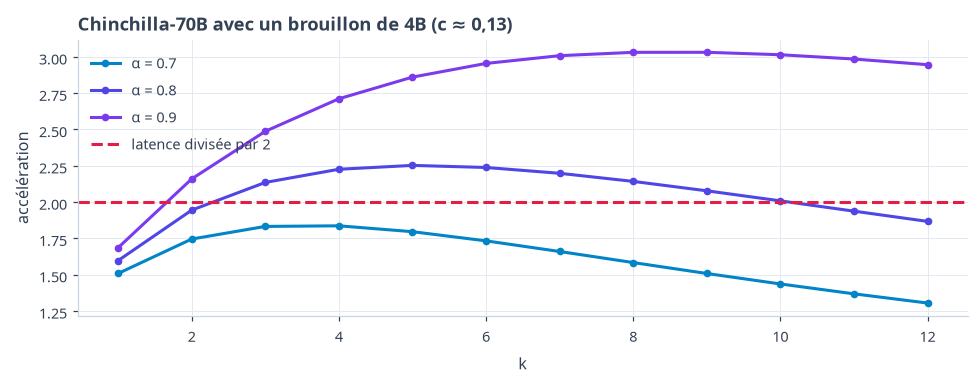

In [2]:
c_book = 1.8 / 14.1
ks = np.arange(1, 13)
S = inf.speculative_speedup(0.8, ks, c_book)
k_opt = inf.optimal_k(0.8, c_book)
print(f"c = {c_book:.3f} ; k optimal = {k_opt} ; accélération = {S[k_opt - 1]:.2f}"
      f" -> latence x {1 / S[k_opt - 1]:.2f}")
fig, ax = plt.subplots(figsize=(9, 3.6))
for a, col in [(0.7, SKY), (0.8, INDIGO), (0.9, VIOLET)]:
    ax.plot(ks, inf.speculative_speedup(a, ks, c_book), "o-", ms=4, color=col, label=f"α = {a}")
ax.axhline(2, color=ROSE, ls="--", label="latence divisée par 2")
ax.set_xlabel("k"); ax.set_ylabel("accélération"); ax.legend()
ax.set_title("Chinchilla-70B avec un brouillon de 4B (c ≈ 0,13)")
plt.tight_layout(); plt.show()

Avec $\alpha = 0{,}8$, l'optimum est vers $k = 4$ à 5 et l'accélération dépasse 2 : la
latence est bien plus que divisée par deux, conforme au livre. Avec $\alpha = 0{,}7$, on
reste sous 2 : le résultat est sensible au taux d'acceptation, donc au domaine.

**Vérification expérimentale** (question 3).

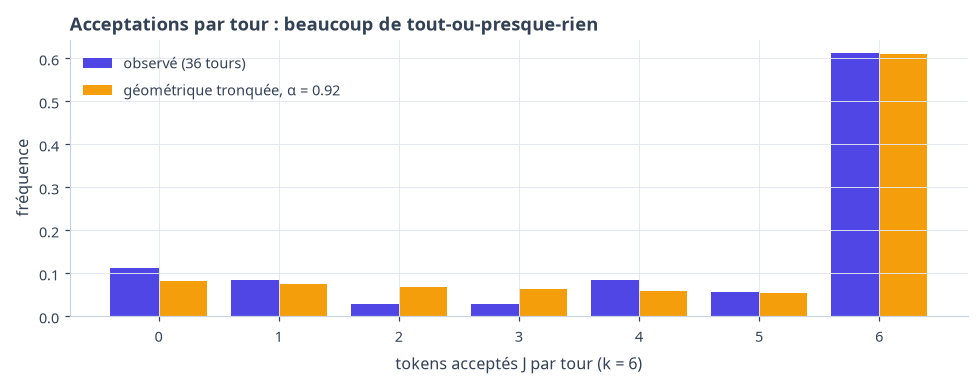

tokens par passe de la cible : mesuré 5.41, formule 5.53


In [3]:
tok_t, tgt = inf.retry_oom(llm.load, llm.MEDIUM)
tok_d, drf = inf.retry_oom(llm.load, llm.SMALL)
stop = inf.eos_ids(tok_t)
p = "Write a short Python class `Stack` with push, pop and peek methods, and a docstring for each."
ids_p = llm._chat_inputs(tok_t, p)["input_ids"][0].tolist()
r = inf.retry_oom(inf.assisted_generate, tgt, ids_p, inf.DraftModelProposer(drf), k=6, max_new_tokens=200, stop=stop)
J = np.array(r.rounds); P = np.array(r.proposed)
full = J[P == 6]  # tours complets (k = 6 propositions)
a_hat = inf.estimate_alpha(full, np.full_like(full, 6))
j_vals = np.arange(7)
theo = np.array([a_hat ** j * (1 - a_hat) for j in range(6)] + [a_hat ** 6])
obs = np.array([(full == j).mean() for j in j_vals])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(j_vals - 0.2, obs, 0.4, color=INDIGO, label=f"observé ({len(full)} tours)")
ax.bar(j_vals + 0.2, theo, 0.4, color=AMBER, label=f"géométrique tronquée, α = {a_hat:.2f}")
ax.set_xlabel("tokens acceptés J par tour (k = 6)"); ax.set_ylabel("fréquence"); ax.legend()
ax.set_title("Acceptations par tour : beaucoup de tout-ou-presque-rien")
plt.tight_layout(); plt.show()
print(f"tokens par passe de la cible : mesuré {len(r.tokens) / r.forwards:.2f},"
      f" formule {float(inf.expected_tokens_per_round(a_hat, 6)):.2f}")

La forme générale (beaucoup de tours entièrement acceptés, un pic à $J = 0$) est bien
celle d'une géométrique tronquée, mais les écarts montrent que l'hypothèse
d'indépendance est approximative : les acceptations viennent **par séries** (passages
faciles, comme la syntaxe d'une classe Python, puis passages difficiles). La formule
donne néanmoins le bon ordre de grandeur pour le nombre de tokens par passe, qui est ce
qui compte pour l'accélération.

> **À retenir.** $\mathbb{E}[\text{tokens par tour}] = \frac{1-\alpha^{k+1}}{1-\alpha}$ ;
> l'accélération exige $\alpha$ élevé **et** $c$ faible, et le $k$ optimal croît avec
> $\alpha$. Mesurez $\alpha$ sur votre propre trafic : il dépend du domaine.

In [4]:
llm.free_gpu()
del tgt, drf

## Exercice 9.8 : Cache KV de Llama 3-70B et utilisateurs simultanés

**Énoncé.** Llama 3-70B : 80 couches, 64 têtes de requêtes, 8 têtes KV (GQA) de dimension
128. On le sert en bf16 sur un nœud de 8 H100 (640 Go), en gardant 10 % de marge.

1. Taille du cache KV par token et par séquence de 128k tokens.
2. Nombre maximal d'utilisateurs simultanés à 128k, 32k et 8k tokens de contexte.
3. Mêmes questions avec un cache quantifié en fp8, puis avec une attention multi-têtes
   classique (64 têtes KV). Que conclure ?

**Rappels.** Cache KV $= 2 \cdot L \cdot h_{kv} \cdot d_h \cdot M$ octets par token
(encadré *Calculating the KV Cache Size* ; cours 3, sections 2 et 3).

**Solution.**

1. $2 \times 80 \times 8 \times 128 \times 2 = 327\,680$ octets par token (320 Kio), soit
   $\approx 43$ Go pour 128k tokens.
2. Mémoire disponible : $0{,}9 \times 640 - 141 \approx 435$ Go ; à 128k tokens :
   $435 / 43 \approx 10$ utilisateurs ; à 32k : environ 40 ; à 8k : environ 165.
3. fp8 double ces nombres ; une attention multi-têtes les divise par 8 : à 128k tokens,
   **un** utilisateur (344 Go de cache) ! Sans GQA, les longs contextes seraient
   impraticables. $\blacksquare$

variante,Kio / token,utilisateurs à 128k,utilisateurs à 32k,utilisateurs à 8k
"GQA-8, bf16",320,10,40,162
"GQA-8, cache fp8",160,20,81,324
"MHA (64 KV), bf16",2560,1,5,20


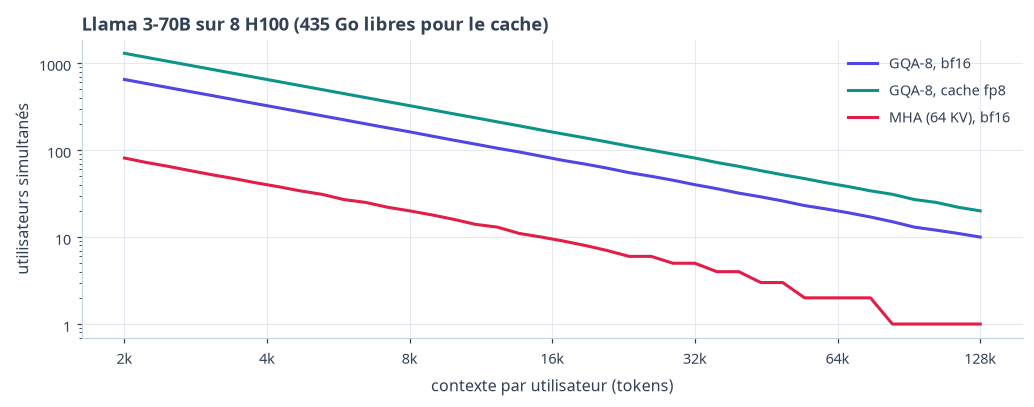

In [5]:
cfg70 = KNOWN_CONFIGS["Llama 3-70B"]
W70 = count_params_config(cfg70) * 2
free_mem = 0.9 * 8 * 80e9 - W70
rows = []
for name, nkv, bpe in [("GQA-8, bf16", 8, 2), ("GQA-8, cache fp8", 8, 1), ("MHA (64 KV), bf16", 64, 2)]:
    per_tok = inf.kv_cache_bytes_gqa(1, 1, cfg70.n_layers, nkv, cfg70.head_dim, bytes_per=bpe)
    rows.append({"variante": name, "Kio / token": per_tok / 1024,
                 **{f"utilisateurs à {S // 1024}k": int(free_mem // (per_tok * S)) for S in [131072, 32768, 8192]}})
assert rows[0]["Kio / token"] == kv_cache_bytes(cfg70, 1) / 1024  # cohérent avec le chapitre 2
display(pd.DataFrame(rows).style.format({"Kio / token": "{:.0f}"}).hide(axis="index"))
ctx = np.geomspace(2048, 131072, 40)
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for (name, nkv, bpe), c in zip([("GQA-8, bf16", 8, 2), ("GQA-8, cache fp8", 8, 1), ("MHA (64 KV), bf16", 64, 2)],
                               [INDIGO, TEAL, ROSE]):
    per_tok = inf.kv_cache_bytes_gqa(1, 1, cfg70.n_layers, nkv, cfg70.head_dim, bytes_per=bpe)
    ax.plot(ctx, np.floor(free_mem / (per_tok * ctx)), color=c, label=name)
ax.set_xscale("log", base=2); ax.set_yscale("log")
plain_log_axis(ax, "x", fmt=lambda v: f"{v / 1024:g}k"); plain_log_axis(ax, "y")
ax.set_xlabel("contexte par utilisateur (tokens)"); ax.set_ylabel("utilisateurs simultanés")
ax.set_title(f"Llama 3-70B sur 8 H100 ({free_mem / GB:.0f} Go libres pour le cache)"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Le nombre d'utilisateurs simultanés est inversement proportionnel au
> contexte et à la taille du cache par token : GQA (÷ 8) et un cache fp8 (÷ 2) ne sont pas
> des détails, ils décident de la viabilité économique des longs contextes.

## Exercice 9.9 : PagedAttention, choisir la taille des blocs

**Énoncé.**

1. Avec des blocs de $b$ tokens, une séquence de longueur $L$ occupe
   $\lceil L/b \rceil$ blocs. Montrer que si $L \bmod b$ est uniforme sur
   $\{0, \dots, b-1\}$, le gaspillage moyen par séquence est $\frac{b-1}{2}$ tokens
   (en comptant un gaspillage nul quand $L$ est multiple de $b$).
2. Vérifier par simulation (1 000 séquences de longueurs log-normales) pour
   $b \in \{1, 4, 16, 64, 256\}$.
3. La table des blocs coûte 4 octets par bloc et par séquence ; pour Qwen2.5-0.5B (12 Kio
   de cache par token), comparer ce coût au gaspillage. Quelle taille de bloc choisir ?

**Rappels.** PagedAttention (cours 3, section 4 ; section *Optimizing the KV cache size*) :
le gaspillage se limite au dernier bloc de chaque séquence.

**Solution.**

1. Le gaspillage vaut $b - (L \bmod b)$ si $L \bmod b \neq 0$, et 0 sinon. Avec
   $r = L \bmod b$ uniforme : $\mathbb{E} = \frac{1}{b}\sum_{r=1}^{b-1}(b - r)
   = \frac{1}{b}\cdot\frac{(b-1)b}{2} = \frac{b-1}{2}$. $\blacksquare$
2. et 3. : simulation ci-dessous. Le coût de la table, $4\lceil L/b\rceil$ octets, est
   négligeable devant le gaspillage ($12\,288 \times (b-1)/2$ octets) dès que $b > 1$ ;
   mais de tout petits blocs fragmentent les accès mémoire du noyau d'attention (lectures
   non contiguës), d'où le compromis pratique de vLLM : 16 tokens.

bloc b,gaspillage moyen (tokens),théorie (b-1)/2,gaspillage (% de la mémoire),table des blocs (octets/séq.),gaspillage (octets/séq.)
1,0.0,0.0,0.00,"2,600",0
4,1.5,1.5,0.22,652,"17,940"
16,7.3,7.5,1.11,164,"89,309"
64,31.7,31.5,4.65,43,"389,923"
256,126.1,127.5,16.24,12,"1,549,124"


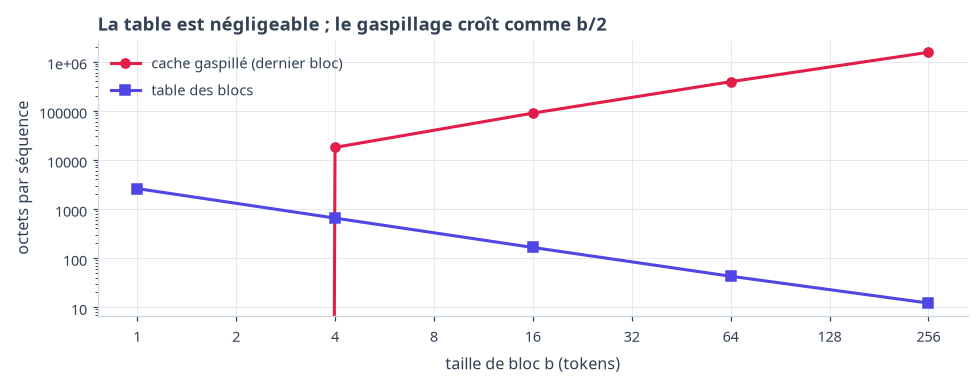

In [6]:
L = np.exp(rng.normal(np.log(500), 0.8, 1000)).astype(int).clip(10, 8000)
kv_tok = kv_cache_bytes(KNOWN_CONFIGS["Qwen2.5-0.5B"], 1)
rows = []
for b in [1, 4, 16, 64, 256]:
    waste = (np.ceil(L / b) * b - L)
    rows.append({"bloc b": b, "gaspillage moyen (tokens)": waste.mean(), "théorie (b-1)/2": (b - 1) / 2,
                 "gaspillage (% de la mémoire)": waste.sum() / (np.ceil(L / b) * b).sum() * 100,
                 "table des blocs (octets/séq.)": 4 * np.ceil(L / b).mean(),
                 "gaspillage (octets/séq.)": waste.mean() * kv_tok})
t99 = pd.DataFrame(rows)
display(t99.style.format({"gaspillage moyen (tokens)": "{:.1f}", "théorie (b-1)/2": "{:.1f}",
                          "gaspillage (% de la mémoire)": "{:.2f}", "table des blocs (octets/séq.)": "{:,.0f}",
                          "gaspillage (octets/séq.)": "{:,.0f}"}).hide(axis="index"))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(t99["bloc b"], t99["gaspillage (octets/séq.)"], "o-", color=ROSE, label="cache gaspillé (dernier bloc)")
ax.plot(t99["bloc b"], t99["table des blocs (octets/séq.)"], "s-", color=INDIGO, label="table des blocs")
ax.set_xscale("log", base=2); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlabel("taille de bloc b (tokens)"); ax.set_ylabel("octets par séquence")
ax.set_title("La table est négligeable ; le gaspillage croît comme b/2"); ax.legend()
plt.tight_layout(); plt.show()

La simulation retrouve $(b-1)/2$ à quelques pourcents près. Même à $b = 256$, le
gaspillage reste modeste en proportion pour des séquences de plusieurs centaines de
tokens, mais il devient important pour les séquences courtes ; avec $b = 16$, il est
inférieur à 2 % de la mémoire.

> **À retenir.** Gaspillage moyen $\approx b/2$ tokens par séquence : comparez-le à la
> longueur typique des séquences. Les petits blocs gaspillent peu ; la limite basse vient
> de l'efficacité des accès mémoire, pas de la table.